In [1]:
import numpy as np  # numeric arrays
import matplotlib.pyplot as plt  # plotting
from sklearn.datasets import load_digits  # built-in digits dataset
from sklearn.model_selection import train_test_split  # split data
from sklearn.neural_network import MLPClassifier  # the neural network (multilayer perceptron)
from sklearn.metrics import accuracy_score, confusion_matrix  # evaluation tools


In [2]:
digits = load_digits()  # load the dataset
print('Images array:', digits.images.shape)  # (number of images, height, width)
print('Flattened data:', digits.data.shape)  # each image as a row of 64 pixel values
print('First 10 labels:', digits.target[:10])  # the digits these images show
print(digits.images[0].astype(int))  # pixel intensities (0-16) of the first image


Images array: (1797, 8, 8)
Flattened data: (1797, 64)
First 10 labels: [0 1 2 3 4 5 6 7 8 9]
[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]


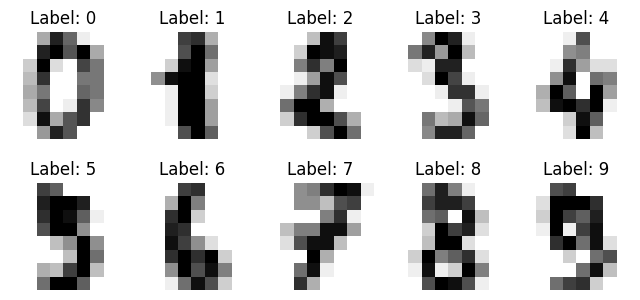

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(8, 3.6))  # grid of 2 rows x 5 columns
for ax, img, label in zip(axes.ravel(), digits.images[:10], digits.target[:10]):
    # go through 10 images
    ax.imshow(img, cmap='gray_r')  # draw the 8x8 image
    ax.set_title(f'Label: {label}')  # show its true digit
    ax.axis('off')  # hide the axes
plt.show()  # display the grid


In [4]:
X = digits.data / 16.0  # scale pixels from 0-16 to 0-1 (helps training)
y = digits.target  # digit label = output
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
        # 80% train / 20% test, same class ratio in both
print('Train:', X_train.shape, '| Test:', X_test.shape)  # check sizes
print('Pixel range:', X.min(), 'to', X.max())  # confirm scaling


Train: (1437, 64) | Test: (360, 64)
Pixel range: 0.0 to 1.0


In [5]:
mlp = MLPClassifier(hidden_layer_sizes=(64, 32),  # two hidden layers: 64 and 32 neurons
                    activation='relu', solver='adam',  # ReLU activation, Adam optimiser
                    max_iter=300, random_state=42)  # up to 300 epochs; fixed seed for repeatability
mlp.fit(X_train, y_train)  # train: forward pass, loss, backpropagation, weight update
print('Layers (input + hidden + output):', mlp.n_layers_)
print('Epochs run:', mlp.n_iter_)
print('Final training loss:', round(mlp.loss_, 4))
print('Weight matrix shapes:', [w.shape for w in mlp.coefs_])  # 64 inputs -> 64 -> 32 -> 10 outputs


Layers (input + hidden + output): 4
Epochs run: 243
Final training loss: 0.0029
Weight matrix shapes: [(64, 64), (64, 32), (32, 10)]


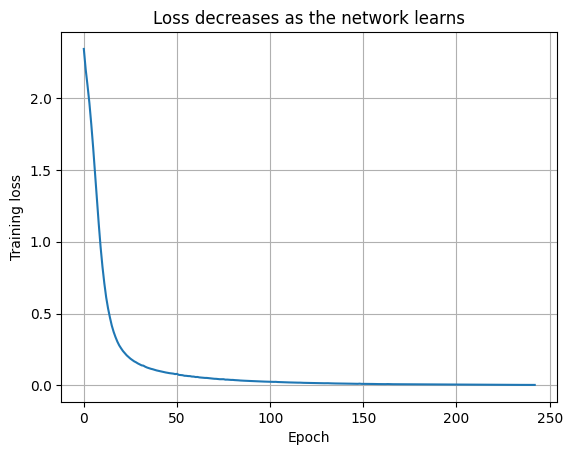

In [6]:
plt.plot(mlp.loss_curve_)  # loss recorded after every epoch
plt.xlabel('Epoch')
plt.ylabel('Training loss')
plt.title('Loss decreases as the network learns')
plt.grid(True)  # light grid for reading values
plt.show()


In [7]:
y_pred = mlp.predict(X_test)  # predicted digit for every test image
print('Test accuracy:', round(accuracy_score(y_test, y_pred), 4))
print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))  # rows = actual digit, columns = predicted digit


Test accuracy: 0.9778
Confusion Matrix:
[[35  0  0  0  1  0  0  0  0  0]
 [ 0 34  0  1  1  0  0  0  0  0]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 35  0  1  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  3  0  0  0  0  0  0 32  0]
 [ 0  0  0  0  0  0  0  0  1 35]]


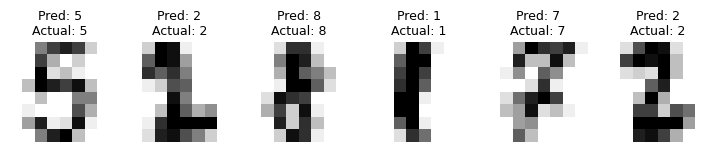

Predicted: [5 2 8 1 7 2]
Actual   : [5 2 8 1 7 2]


In [8]:
fig, axes = plt.subplots(1, 6, figsize=(9, 2))  # one row of 6 images
for ax, i in zip(axes, range(6)):  # first 6 test images
    ax.imshow(X_test[i].reshape(8, 8), cmap='gray_r')  # turn 64 values back into an 8x8 image
    ax.set_title(f'Pred: {y_pred[i]}\nActual: {y_test[i]}', fontsize=9)  # predicted vs true digit
    ax.axis('off')
plt.show()
print('Predicted:', y_pred[:6])
print('Actual   :', y_test[:6])
